In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from starter_pack.code.utils import *
# kernal
K = np.array([1, 4, 6, 4, 1], dtype=np.float64) / 16.0

In [ ]:
def blur_axis(im, k, axis):
    """1D convolution using reflect padding, same output size."""
    r = len(k) // 2
    pad = [(0, 0)] * im.ndim
    pad[axis] = (r, r)
    p = np.pad(im, pad, mode="reflect")
    n = im.shape[axis]
    out = np.zeros(im.shape, dtype=np.float64)
    for i, w in enumerate(k):                    # loop over taps, not pixels
        out += w * np.take(p, np.arange(i, i + n), axis=axis)
    return out

In [ ]:
def blur(im):
    """Blur with k along x and y."""
    return blur_axis(blur_axis(im, K, 0), K, 1)

In [ ]:
def reduce(im):
    """Blur, then reduce by a factor of 2."""
    return blur(im)[::2, ::2]

In [18]:
def expand(im, shape=None):
    """Put each pixel at the top-left of a 2x2 block of zeros, blur, multiply by 4.
    If `shape` is given, drop the extra last row/column (odd-sized targets)."""
    H, W = im.shape[:2]
    up = np.zeros((2 * H, 2 * W) + im.shape[2:], dtype=np.float64)
    up[::2, ::2] = im
    out = 4.0 * blur(up)
    if shape is not None:
        out = out[:shape[0], :shape[1]]
    return out

In [19]:
def gaussian_pyramid(im, levels):
    gp = [im.astype(np.float64)]
    for _ in range(levels - 1):
        gp.append(reduce(gp[-1]))
    return gp

In [20]:
def laplacian_pyramid(gp):
    lp = [gp[i] - expand(gp[i + 1], gp[i].shape) for i in range(len(gp) - 1)]
    lp.append(gp[-1])                            # smallest Gaussian level itself
    return lp

In [21]:
def reconstruct(lp):
    cur = lp[-1]
    for L in reversed(lp[:-1]):
        cur = expand(cur, L.shape) + L
    return cur

In [ ]:
def pyramid_canvas(levels, boost=None):
    """ Laplacian display"""
    H = levels[0].shape[0]
    W = sum(l.shape[1] for l in levels) + 10 * (len(levels) - 1)
    shape = (H, W) + levels[0].shape[2:]
    canvas = np.ones(shape)
    x = 0
    for i, l in enumerate(levels):
        last = i == len(levels) - 1                    # smallest Gaussian level: show as is
        d = l if (boost is None or last) else 0.5 + boost * l   # zero -> mid-gray
        canvas[:l.shape[0], x:x + l.shape[1]] = np.clip(d, 0, 1)
        x += l.shape[1] + 10
    return canvas

image shape: (418, 600, 3)
level shapes: [(418, 600), (209, 300), (105, 150), (53, 75), (27, 38)]
max abs error: 0.0
pyramid size / image size: 1.3327392344497608


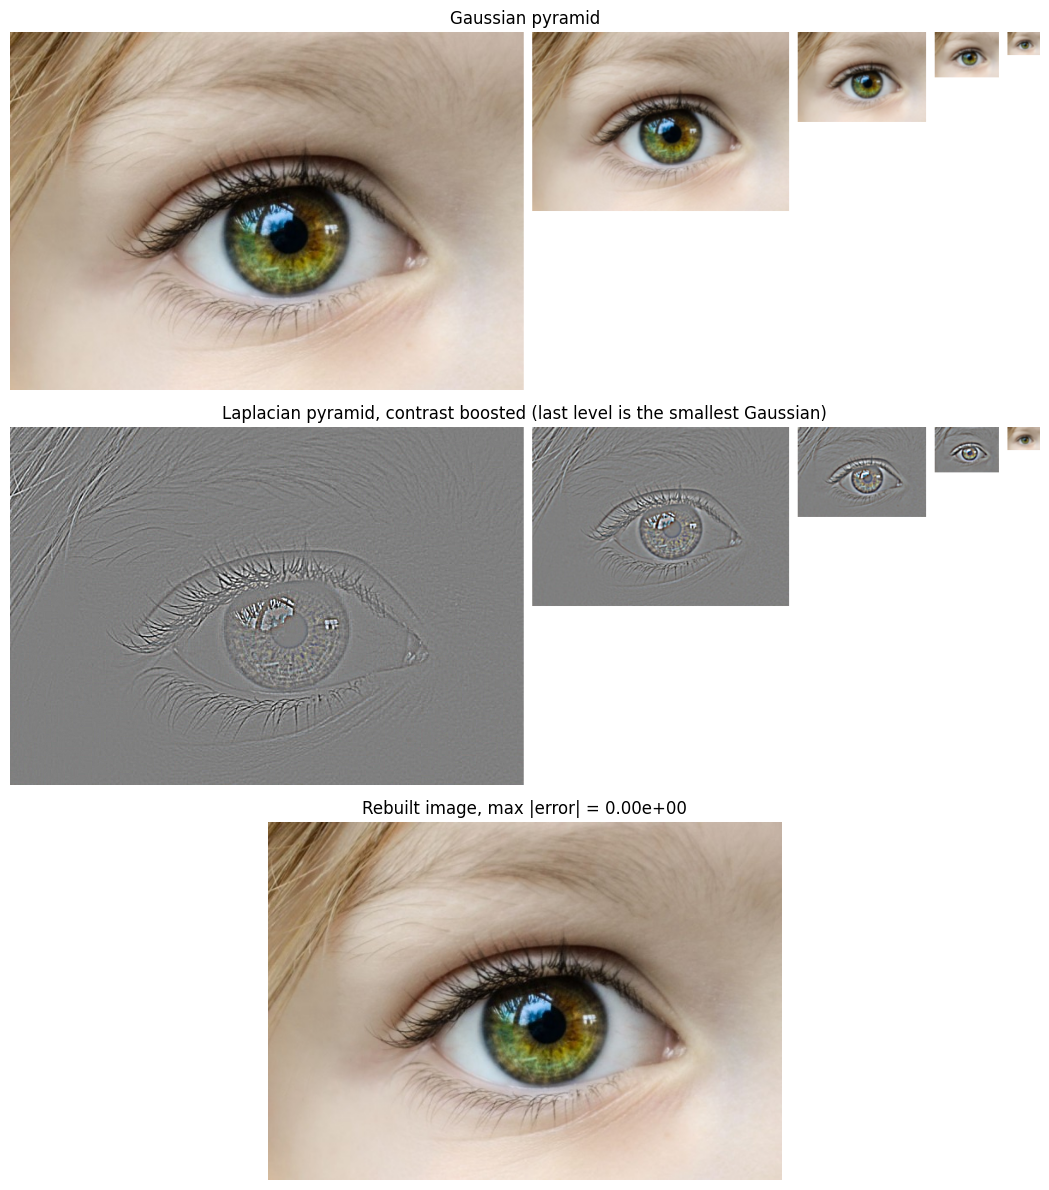

In [ ]:
if __name__ == "__main__":
    
    path = "starter_pack/images/part2_frequencies/eye.jpg"
    im = load_image(path)                         # color; use gray=True for grayscale
    levels = 5
    gp = gaussian_pyramid(im, levels)
    lp = laplacian_pyramid(gp)
    rec = reconstruct(lp)
    err = np.abs(rec - im)
    print("image shape:", im.shape)
    print("level shapes:", [g.shape[:2] for g in gp])
    print("max abs error:", err.max())
    total = sum(g.shape[0] * g.shape[1] for g in gp)
    print("pyramid size / image size:", total / (im.shape[0] * im.shape[1]))
 
    fig, ax = plt.subplots(3, 1, figsize=(12, 12))
    cm = "gray" if im.ndim == 2 else None
    ax[0].imshow(pyramid_canvas(gp), cmap=cm); ax[0].set_title("Gaussian pyramid")
    ax[1].imshow(pyramid_canvas(lp, boost=3.0), cmap=cm)
    ax[1].set_title("Laplacian pyramid, contrast boosted ")
    ax[2].imshow(np.clip(rec, 0, 1), cmap=cm)
    ax[2].set_title(f"Rebuilt image, max |error| = {err.max():.2e}")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.savefig("pyramids.png", dpi=150); plt.show()